# 쓰레기 이미지 분류

[Colab에서 열기](https://colab.research.google.com/github/njw257/bigdataprogramming_hackathon/blob/main/garbage_classifier_v2_added.ipynb)

계명대학교 경영정보학과 남종욱 · 빅데이터프로그래밍 1차 해커톤

쓰레기 이미지를 12개 클래스로 분류하는 4블록 CNN을 PyTorch로 구현했습니다. Kaggle Garbage Classification을 기본 데이터로 사용하고, V2에서 중복을 제거한 이미지로 biological, plastic, trash, metal 클래스를 보강했습니다.

| 시험셋 | 최종 모델 정확도 |
|---|---:|
| V1 시험 1,550장 | **87.48%** |
| V2 보류 시험 156장 | **70.51%** |

Colab에서 실행하면 `kagglehub`로 데이터를 가져오고, 노트북에 내장된 가중치로 시험 성능을 확인할 수 있습니다. 마지막 셀에서 별도 이미지를 업로드하면 최종 모델의 상위 3개 예측을 확인할 수 있습니다.

## 1 Kaggle 데이터 수집과 V1 EDA

[V1 Garbage Classification](https://www.kaggle.com/datasets/mostafaabla/garbage-classification)과 [V2 Garbage Classification v12](https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2/versions/12)를 사용합니다. 캐시가 없으면 KaggleHub가 런타임 캐시를 채웁니다.

In [1]:
# Kaggle 수집·유사 이미지 검사 라이브러리
%pip install -q kagglehub ImageHash

In [2]:
import kagglehub
from pathlib import Path

# 지정 데이터셋을 가져오고 저장 경로 확인
data_path = Path(kagglehub.dataset_download("mostafaabla/garbage-classification"))
print("데이터 경로:", data_path)

# 폴더 구조 확인
print("내부 항목:", sorted(p.name for p in data_path.iterdir()))
# 클래스별 폴더가 있는 경로
image_dir = data_path / "garbage_classification"

# 클래스별 이미지 수 집계
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = {
    folder.name: sum(
        p.is_file() and p.suffix.lower() in extensions
        for p in folder.rglob("*")
    )
    for folder in sorted(image_dir.iterdir())
    if folder.is_dir()
}

for name, count in class_counts.items():
    print(f"{name}: {count:,}장")

print(f"\n클래스 수: {len(class_counts)}개")
print(f"전체 이미지: {sum(class_counts.values()):,}장")

Using Colab cache for faster access to the 'garbage-classification' dataset.
데이터 경로: /kaggle/input/garbage-classification
내부 항목: ['garbage_classification']
battery: 945장
biological: 985장
brown-glass: 607장
cardboard: 891장
clothes: 5,325장
green-glass: 629장
metal: 769장
paper: 1,050장
plastic: 865장
shoes: 1,977장
trash: 697장
white-glass: 775장

클래스 수: 12개
전체 이미지: 15,515장


In [3]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# 클래스별 이미지 수 시각화
plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45, ha="right")
plt.ylabel("Image count")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

# 클래스별 이미지 3장을 고정된 난수로 선택
rng = random.Random(42)
fig, axes = plt.subplots(len(class_counts), 3, figsize=(9, 3 * len(class_counts)))

for row, name in enumerate(class_counts):
    files = sorted(
        p for p in (image_dir / name).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    for col, path in enumerate(rng.sample(files, 3)):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))
        axes[row, col].set_title(name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 2 V1 상태 확인과 중복 처리

V1의 손상 여부와 크기를 확인하고, 같은 파일의 중복과 레이블 충돌을 원래 실험과 같은 방식으로 처리합니다.

In [4]:
import pandas as pd

records, bad_files = [], []

# 모든 이미지를 읽어 크기·색상 모드·손상 여부 확인
for name in class_counts:
    for path in sorted((image_dir / name).rglob("*")):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue
        try:
            with Image.open(path) as img:
                img.load()  # 실제 픽셀까지 읽어 오류 확인
                records.append({
                    "path": str(path), "class": name,
                    "width": img.width, "height": img.height, "mode": img.mode
                })
        except (OSError, ValueError) as error:
            bad_files.append((str(path), str(error)))

images_df = pd.DataFrame(records)

print("정상 이미지:", len(images_df))
print("손상 이미지:", len(bad_files))
print("\n이미지 크기 요약:\n", images_df[["width", "height"]].describe().round(1))
print("\n색상 모드별 수량:\n", images_df["mode"].value_counts())
print("\n손상 파일 예시:", bad_files[:5])
import hashlib

# 파일 내용으로 해시 생성: 내용이 같으면 같은 해시가 나옵니다.
images_df["hash"] = images_df["path"].apply(
    lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
)

# 중복 그룹의 이미지 수와 클래스 확인
duplicates = images_df[images_df.duplicated("hash", keep=False)]
duplicate_groups = duplicates.groupby("hash").agg(
    count=("path", "size"),
    classes=("class", lambda x: sorted(set(x)))
)

print("중복 그룹 수:", len(duplicate_groups))
print("중복 여분 이미지 수:", images_df.duplicated("hash").sum())
print("클래스가 서로 다른 중복 그룹 수:",
      duplicate_groups["classes"].apply(len).gt(1).sum())
print("\n중복 그룹 예시:\n", duplicate_groups.head(10).to_string(index=False))
conflict_hashes = duplicate_groups.index[duplicate_groups["classes"].apply(len).gt(1)]
# 레이블이 충돌하는 이미지 제외: 제외 목록은 보고서용으로 보관
conflict_rows = images_df[images_df["hash"].isin(conflict_hashes)].copy()
clean_df = images_df[~images_df["hash"].isin(conflict_hashes)].copy()

# 같은 클래스의 동일 파일은 한 장만 유지
duplicate_rows = clean_df[clean_df.duplicated("hash")].copy()
clean_df = clean_df.drop_duplicates("hash").reset_index(drop=True)

print("레이블 충돌로 제외:", len(conflict_rows))
print("동일 클래스 중복으로 제외:", len(duplicate_rows))
print("최종 이미지 수:", len(clean_df))
print("\n클래스별 수량:\n", clean_df["class"].value_counts().sort_index())

정상 이미지: 15515
손상 이미지: 0

이미지 크기 요약:
          width   height
count  15515.0  15515.0
mean     349.8    351.7
std      117.5    149.4
min       51.0    100.0
25%      234.0    224.0
50%      400.0    384.0
75%      400.0    533.0
max      888.0    936.0

색상 모드별 수량:
 mode
RGB    15481
P         34
Name: count, dtype: int64

손상 파일 예시: []
중복 그룹 수: 18
중복 여분 이미지 수: 19
클래스가 서로 다른 중복 그룹 수: 3

중복 그룹 예시:
  count       classes
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2     [clothes]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
레이블 충돌로 제외: 6
동일 클래스 중복으로 제외: 16
최종 이미지 수: 15493

클래스별 수량:
 class
battery         945
biological      985
brown-glass     607
cardboard       891
clothes        5324
green-glass     614
metal           768
paper          1050
plastic         863
shoes          1977
trash           697
white-glass     772
Name: count, dtype: int64


## 3 기존 분할과 두 모델의 가중치

직접 학습한 V1 가중치, V1 원래 분할, V2 추가 학습에서 선택된 가중치를 셀에 포함했습니다.

In [5]:
#@title V1·V2 학습 가중치와 V1 원래 분할 (접힌 데이터 셀)
# 아래 문자열은 기존 학습 결과입니다. 모델 구조와 학습 함수는 바꾸지 않습니다.
import base64, io, json, zlib

EMBEDDED_MODEL_B64 = """
...
"""
EMBEDDED_HISTORY_B64 = """
eNp9lM1qG0EQhN9lz0JM/3f7VYIxQgQSMHGIjS/B7+5VgqKZapS97TJ8VdtdNV9+b19/vpy/bQ902N5+nb7/eHp+eX3dX49qEddvp/N5exhHYzts76fn6Yz4
3y/XE8rycfgHZYSyUCG0coVSiSxQJ5mhgtBRjFCXWqHDfXXqZjVBdYWOY2UqQiNGTQ8ojMGrQnBMCoYKmWmgEMMX6m6Dkhbq5chE9UYlxWEEpwM1E6YRleP2
0KQQqBDKGIwwAt9JpatvlXkaiVSPbL7DwXcqwzQk6o7vagocuNG4mrwJ5Jq9fYc+QWkg1ZwJqEkGvoMEfCfNXokalioRK2Q4ZIhcuOqMZcRqtnSkDkyHCuyO
Rs5YaVix5tb3oN4py2WstSqEzRWnVkcdFE0BY+1Eq/EE462DYtS2l/Ef4+6Wq8Rwno/Pcq2coqP9BQqwGghI3Ik4tW5ytTTWuF6nN4lLgReJXKbfysl/bs8V
S0aALUjjPn26N5rWTtaSJoEL3su23lspOdeTWz2ZO5YlwbkMzI3Hx+MnxoQRLg==
"""
EMBEDDED_SPLIT_B64 = """
...
"""
EXPECTED_MODEL_SHA256 = "90341f5485e79c645ca1078613f9a2498b41f7552f795e03455f465b3c605cc5"
EXPECTED_DATA_SHA256 = "b6b506e1be90c15e8b3d3e72460f30fa2425402eef7912118f5245ee6434f271"

EXPECTED_V2_MODEL_SHA256 = "6b3c836e338e631a104db218c620891da182dc2b3e27feee808b73689b631eb7"
EMBEDDED_V2_MODEL_B64 = (
    "..."
)

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 클래스 이름을 정수 레이블로 변환: 모든 데이터에 같은 매핑 사용
classes = sorted(clean_df["class"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}

# 크기를 통일하고 픽셀 값을 [0, 1]에서 [-1, 1]로 변환
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

class GarbageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["path"]) as img:
            image = self.transform(img.convert("RGB"))
        return image, class_to_idx[row["class"]]


from torch import nn

class FilterCNN(nn.Module):
    def __init__(self, num_classes, channels):
        super().__init__()
        layers = []
        cin = 3

        for cout in channels[:3]:
            layers += [
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2)
            ]
            cin = cout

        self.features = nn.Sequential(*layers)

        # 기존 DeeperCNN과 초기화 순서를 맞춤
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels[3], num_classes)
        )
        self.features.extend([
            nn.Conv2d(channels[2], channels[3], 3, padding=1),
            nn.BatchNorm2d(channels[3]),
            nn.ReLU(),
            nn.MaxPool2d(2)
        ])

    def forward(self, x):
        return self.classifier(self.features(x))

class WideCNN(FilterCNN):
    def __init__(self, num_classes):
        super().__init__(num_classes, (64, 128, 256, 256))

def load_embedded_checkpoint(encoded, expected_sha256):
    model_bytes = zlib.decompress(base64.b64decode(encoded))
    if hashlib.sha256(model_bytes).hexdigest() != expected_sha256:
        raise ValueError("내장된 모델 파일의 SHA-256이 일치하지 않습니다.")
    checkpoint = torch.load(io.BytesIO(model_bytes), map_location="cpu", weights_only=True)
    assert checkpoint["class_to_idx"] == class_to_idx
    assert checkpoint["channels"] == [64, 128, 256, 256] and checkpoint["image_size"] == 128
    assert checkpoint["mean"] == checkpoint["std"] == [0.5] * 3
    return checkpoint

set_signature = sorted(
    label + "/" + Path(path).name + "\t" + digest
    for label, path, digest in zip(clean_df["class"], clean_df["path"], clean_df["hash"])
)
assert hashlib.sha256("\n".join(set_signature).encode()).hexdigest() == EXPECTED_DATA_SHA256, (
    "V1 이미지가 원래 학습에 사용한 파일과 다릅니다."
)
original_split = pd.DataFrame(
    json.loads(zlib.decompress(base64.b64decode(EMBEDDED_SPLIT_B64))),
    columns=["class", "filename", "split"]
)
original_split["path"] = [
    str(image_dir / name / filename)
    for name, filename in zip(original_split["class"], original_split["filename"])
]
original_train, original_val, original_test = [
    original_split[original_split["split"] == part].copy() for part in ("train", "val", "test")
]
assert [len(original_train), len(original_val), len(original_test)] == [12394, 1549, 1550]

baseline_checkpoint = load_embedded_checkpoint(EMBEDDED_MODEL_B64, EXPECTED_MODEL_SHA256)
v2_checkpoint = load_embedded_checkpoint(EMBEDDED_V2_MODEL_B64, EXPECTED_V2_MODEL_SHA256)
assert v2_checkpoint["selected_additional_epoch"] == 4
baseline_model = WideCNN(len(classes)).to(device)
baseline_model.load_state_dict(baseline_checkpoint["model_state"])
model = WideCNN(len(classes)).to(device)
model.load_state_dict(v2_checkpoint["model_state"])
baseline_model.eval()
model.eval()
test_transform = transform
print(f"평가 장치: {device} | V1: {baseline_checkpoint['selected_epoch']} epoch | V2 추가 학습: {v2_checkpoint['selected_additional_epoch']} epoch")

평가 장치: cuda | V1: 19 epoch | V2 추가 학습: 4 epoch


## 4 V2 선별과 시험 분할

V2 v12의 `original`만 사용합니다. V1 전체와 SHA-256·RGB 픽셀 해시를 비교하고 pHash 거리 4 이하의 유사 후보는 보류합니다. 각 클래스 분할은 처음 사용한 후보 순서와 seed 42로 재구성합니다.

In [7]:
V2_HANDLE = "sumn2u/garbage-classification-v2/versions/12"
EXTRA_TARGETS = {
    "biological": 1000, "plastic": 1000, "trash": 800,
    "metal": 500, "shoes": 300, "battery": 200
}
ADDITIONAL_LR = 0.0003
ADDITIONAL_EPOCHS = 10
SEED = 42
PHASH_DISTANCE = 4  # 유사도 후보 기준이며 라벨을 결정하는 값이 아님

assert set(EXTRA_TARGETS).issubset(class_to_idx) and not any("glass" in c for c in EXTRA_TARGETS)
assert PHASH_DISTANCE == 4, "아래 pHash 인덱스는 거리 4를 기준으로 구성되어 있습니다."

v2_path = Path(kagglehub.dataset_download(V2_HANDLE))
original_dirs = [v2_path / "original"] if (v2_path / "original").is_dir() else list(v2_path.rglob("original"))
assert len(original_dirs) == 1, "V2의 original 폴더를 하나로 식별할 수 없습니다. 경로를 확인해 주세요."
v2_image_dir = original_dirs[0]
inventory = []
for folder in sorted(v2_image_dir.iterdir()):
    if folder.is_dir():
        paths = sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in extensions)
        inventory.extend({"path": str(p), "class": folder.name} for p in paths)
v2_inventory = pd.DataFrame(inventory)
assert not v2_inventory.empty, "V2 original 폴더에 이미지가 없습니다."
print("V2 실제 클래스별 수량:\n", v2_inventory["class"].value_counts().sort_index())
print("전체 V2 이미지:", len(v2_inventory))
v2_candidates = v2_inventory[v2_inventory["class"].isin(EXTRA_TARGETS)].reset_index(drop=True)
assert not v2_candidates.empty, "추가 대상 클래스의 폴더 이름을 확인해 주세요."

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.
V2 실제 클래스별 수량:
 class
battery        756
biological     699
cardboard     1411
clothes       1892
glass         1736
metal          930
paper         1336
plastic       1597
shoes         1449
trash          453
Name: count, dtype: int64
전체 V2 이미지: 12259


In [8]:
import imagehash
from PIL import ImageOps
from collections import defaultdict

def image_fingerprint(path, file_hash=None):
    with Image.open(path) as img:
        rgb = ImageOps.exif_transpose(img).convert("RGB")
        pixels = hashlib.sha256(str(rgb.size).encode() + b"|" + rgb.tobytes()).hexdigest()
        perceptual = str(imagehash.phash(rgb, hash_size=8))
    return {
        "sha256": file_hash or hashlib.sha256(Path(path).read_bytes()).hexdigest(),
        "pixel_hash": pixels, "phash": perceptual
    }

# 64비트를 5구간으로 나누면 4비트 이내 차이는 적어도 한 구간이 일치
def hash_keys(value):
    return [(band, (value >> (13 * band)) & ((1 << min(13, 64 - 13 * band)) - 1))
            for band in range(5)]

def add_hash(index, hashes, value, row_id):
    hashes[row_id] = value
    for key in hash_keys(value):
        index[key].add(row_id)

def nearby_hashes(index, hashes, value):
    possible = set()
    for key in hash_keys(value):
        possible.update(index.get(key, ()))
    return [row_id for row_id in possible
            if (hashes[row_id] ^ value).bit_count() <= PHASH_DISTANCE]

# 기존 원본 전체의 해시: test와 겹친 외부 이미지도 학습에 들어가지 않게 함
base_sha = set(images_df["hash"])
base_pixels = set()
base_index, base_hashes = defaultdict(set), {}
for row_id, row in images_df.reset_index(drop=True).iterrows():
    fingerprint = image_fingerprint(row["path"], row["hash"])
    base_pixels.add(fingerprint["pixel_hash"])
    add_hash(base_index, base_hashes, int(fingerprint["phash"], 16), row_id)
    if (row_id + 1) % 2000 == 0:
        print(f"기존 이미지 해시 확인: {row_id + 1:,}/{len(images_df):,}")

audit_rows = []
for row_id, row in v2_candidates.iterrows():
    record = {"path": row["path"], "class": row["class"], "status": "candidate"}
    try:
        record.update(image_fingerprint(row["path"]))
    except (OSError, ValueError) as error:
        record.update(status="unreadable", error=str(error))
    audit_rows.append(record)
    if (row_id + 1) % 500 == 0:
        print(f"V2 이미지 해시 확인: {row_id + 1:,}/{len(v2_candidates):,}")
assert any(row["status"] == "candidate" for row in audit_rows), "읽을 수 있는 V2 추가 대상 이미지가 없습니다."
v2_audit = pd.DataFrame(audit_rows)

# 먼저 V2 내부의 동일 이미지·다른 라벨 충돌을 모두 제외
readable_mask = v2_audit["status"] == "candidate"
readable_rows = v2_audit[readable_mask]
for key in ["sha256", "pixel_hash"]:
    valid = readable_rows
    conflict_keys = valid.groupby(key)["class"].nunique()
    conflict_keys = set(conflict_keys[conflict_keys > 1].index)
    mask = readable_mask & v2_audit[key].isin(conflict_keys)
    v2_audit.loc[mask, "status"] = "label_conflict"

for row_id, row in v2_audit[v2_audit["status"] == "candidate"].iterrows():
    if row["sha256"] in base_sha or row["pixel_hash"] in base_pixels:
        v2_audit.loc[row_id, "status"] = "duplicate_of_original"
for key in ["sha256", "pixel_hash"]:
    valid = v2_audit[v2_audit["status"] == "candidate"]
    redundant = valid.index[valid.duplicated(key, keep="first")]
    v2_audit.loc[redundant, "status"] = "duplicate_within_v2"

# 유사 후보는 원본과의 비교, V2 상호 비교 모두 보류
extra_index, extra_hashes = defaultdict(set), {}
review_ids = set()
for row_id, row in v2_audit[v2_audit["status"] == "candidate"].iterrows():
    value = int(row["phash"], 16)
    if nearby_hashes(base_index, base_hashes, value):
        review_ids.add(row_id)
    neighbors = nearby_hashes(extra_index, extra_hashes, value)
    if neighbors:
        review_ids.add(row_id)
        review_ids.update(neighbors)
    add_hash(extra_index, extra_hashes, value, row_id)
if review_ids:
    v2_audit.loc[sorted(review_ids), "status"] = "near_duplicate_review"
novel_v2 = v2_audit[v2_audit["status"] == "candidate"].copy()
print("제외·보류 내역:\n", pd.crosstab(v2_audit["class"], v2_audit["status"]))
print("신규 후보 수:\n", novel_v2["class"].value_counts().sort_index())
assert not novel_v2.empty, "중복·유사 후보를 제외한 신규 이미지가 없습니다. 추가 학습을 진행하지 않습니다."

기존 이미지 해시 확인: 2,000/15,515
기존 이미지 해시 확인: 4,000/15,515
기존 이미지 해시 확인: 6,000/15,515
기존 이미지 해시 확인: 8,000/15,515
기존 이미지 해시 확인: 10,000/15,515
기존 이미지 해시 확인: 12,000/15,515
기존 이미지 해시 확인: 14,000/15,515
V2 이미지 해시 확인: 500/5,884
V2 이미지 해시 확인: 1,000/5,884
V2 이미지 해시 확인: 1,500/5,884
V2 이미지 해시 확인: 2,000/5,884
V2 이미지 해시 확인: 2,500/5,884
V2 이미지 해시 확인: 3,000/5,884
V2 이미지 해시 확인: 3,500/5,884
V2 이미지 해시 확인: 4,000/5,884
V2 이미지 해시 확인: 4,500/5,884
V2 이미지 해시 확인: 5,000/5,884
V2 이미지 해시 확인: 5,500/5,884
제외·보류 내역:
 status      candidate  duplicate_of_original
class                                       
battery             0                    756
biological         60                    639
metal             319                    611
plastic           964                    633
shoes               0                   1449
trash             222                    231
신규 후보 수:
 class
biological     60
metal         319
plastic       964
trash         222
Name: count, dtype: int64


In [9]:
parts, selection_rows = [], []
for name, target in EXTRA_TARGETS.items():
    group = novel_v2[novel_v2["class"] == name]
    count = min(len(group), target)
    if count < 10:
        selection_rows.append({"class": name, "available": len(group), "selected": 0,
                               "train": 0, "val": 0, "test": 0})
        continue
    chosen = group.sample(n=count, random_state=SEED).reset_index(drop=True)
    holdout_count = max(1, round(count * 0.1))
    chosen["split"] = (["test"] * holdout_count + ["val"] * holdout_count
                       + ["train"] * (count - 2 * holdout_count))
    parts.append(chosen)
    selection_rows.append({"class": name, "available": len(group), "selected": count,
                           "train": count - 2 * holdout_count,
                           "val": holdout_count, "test": holdout_count})
assert parts, "분할할 수 있는 신규 데이터가 없습니다. 선별 결과를 확인해 주세요."
extra_split = pd.concat(parts, ignore_index=True)
extra_split["source"] = "sumn2u/garbage-classification-v2"
extra_split["source_version"] = 12
extra_split["original_label"] = extra_split["class"]
# pHash는 64비트 정밀도 보존을 위해 16진수 문자열 그대로 저장
selection_df = pd.DataFrame(selection_rows)

extra_train = extra_split[extra_split["split"] == "train"].copy()
extra_val = extra_split[extra_split["split"] == "val"].copy()
extra_test = extra_split[extra_split["split"] == "test"].copy()
combined_train = pd.concat([original_train, extra_train], ignore_index=True)
combined_val = pd.concat([original_val, extra_val], ignore_index=True)

# 분할 경로의 중복 확인: 이미지 내용 중복은 앞 셀에서 검사
frames = [combined_train, combined_val, original_test, extra_test]
path_sets = [set(frame["path"]) for frame in frames]
assert all(path_sets[i].isdisjoint(path_sets[j]) for i in range(4) for j in range(i + 1, 4))
assert len(original_test) == 1550 and len(original_val) == 1549
print("V2 선택·분할 수량:\n", selection_df.to_string(index=False))
print(f"학습 {len(combined_train):,} / 검증 {len(combined_val):,}")
print(f"기존 시험 {len(original_test):,} / V2 holdout {len(extra_test):,}")
print("추가하지 않은 클래스도 원래 train에서 계속 학습합니다:", classes)
assert v2_checkpoint["external_dataset"] == V2_HANDLE
assert len(v2_inventory) == 12259 and len(v2_candidates) == 5884
expected_v2 = {
    "biological": (48, 6, 6), "plastic": (772, 96, 96),
    "trash": (178, 22, 22), "metal": (255, 32, 32),
}
actual_v2 = pd.crosstab(extra_split["class"], extra_split["split"])[["train", "val", "test"]]
assert {name: tuple(row) for name, row in actual_v2.iterrows()} == expected_v2, (
    "V2 분할 수량이 실험 기록과 다릅니다."
)

# 원래 Colab CSV에는 절대 경로가 포함되어 있으므로 당시 경로로도 검사합니다.
paths = extra_split["path"].map(lambda path: Path(path).relative_to(v2_image_dir).as_posix())
colab_roots = (
    v2_image_dir.as_posix(), "/kaggle/input/garbage-classification-v2/original",
    "/kaggle/input/datasets/sumn2u/garbage-classification-v2/original",
    "/root/.cache/kagglehub/datasets/sumn2u/garbage-classification-v2/versions/12/original",
)
for root in dict.fromkeys(colab_roots):
    csv = extra_split.assign(path=root + "/" + paths).to_csv(index=False, lineterminator="\n")
    if hashlib.sha256(csv.encode()).hexdigest() == v2_checkpoint["extra_split_sha256"]:
        print("V2 분할이 당시 Colab 분할과 일치합니다.")
        break
else:
    print("V2 분할을 당시 정렬과 seed로 재구성했습니다. 저장된 분할 해시는 원래 절대 경로를 포함합니다.")

V2 선택·분할 수량:
      class  available  selected  train  val  test
biological         60        60     48    6     6
   plastic        964       964    772   96    96
     trash        222       222    178   22    22
     metal        319       319    255   32    32
     shoes          0         0      0    0     0
   battery          0         0      0    0     0
학습 13,647 / 검증 1,705
기존 시험 1,550 / V2 holdout 156
추가하지 않은 클래스도 원래 train에서 계속 학습합니다: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
V2 분할이 당시 Colab 분할과 일치합니다.


## 5 이어 학습 방법

원래 4블록 WideCNN에서 시작해 V1 학습 12,394장과 선별한 V2 학습 1,253장으로 이어 학습했습니다. V1·V2 합본 검증 1,705장에서 정확도를 비교했습니다. Adam 0.0003, 배치 32, 최대 10 epoch이며 4번째 epoch가 선택되었습니다. 기본값은 이미 저장한 V2 가중치를 사용합니다.

### 과적합 점검과 하이퍼파라미터 비교


본 프로젝트는 Kaggle Garbage Classification을 바탕으로 쓰레기 이미지를 12개 클래스로 분류하는 4블록 CNN을 PyTorch로 구현했다. 분류가 어려웠던 biological, plastic, trash, metal 클래스는 Garbage Classification V2에서 중복을 제거한 이미지로 보강했다.

학습률, Dropout, BatchNorm, 블록 수, 필터 수, 입력 크기를 검증 정확도로 비교했다. 데이터 증강은 회전·이동·좌우 반전과 밝기·대비 조정을 비교했다. V1의 4블록 모델에서 검증 정확도는 증강·Dropout 미적용 83.86%, Dropout 0.1 적용 82.50%, 기하·조명 증강 적용 82.57%였다. 이 비교에 따라 최종 설정에는 Dropout과 증강을 적용하지 않았다.

과적합 가능성은 학습·검증 곡선으로 점검했다. V2 추가 학습 후반에는 학습 정확도가 계속 올랐지만 검증 정확도는 약 85%에 머물렀다. 따라서 검증 정확도가 처음 최고값인 85.57%에 도달한 4번째 epoch의 가중치를 선택했다.

최종 모델은 지정 데이터의 시험 이미지 1,550장에서 정확도 87.48%, Macro F1 84.33%, Macro Recall 84.20%를 기록했다. 제출 노트북에서는 Kaggle 데이터를 가져와 내장 가중치로 평가하고, 마지막 셀에서 별도 이미지를 업로드해 예측할 수 있다.

- 기본 데이터 [Kaggle Garbage Classification](https://www.kaggle.com/datasets/mostafaabla/garbage-classification)
- 추가 데이터 [Kaggle Garbage Classification V2 v12](https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2/versions/12)

In [10]:
criterion = nn.CrossEntropyLoss()

# optimizer가 주어지면 학습, 없으면 검증
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        loss_sum += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)

    return loss_sum / total, correct / total
def fit_experiment(name, model_factory, dataset, lr=0.005, epochs=20, initial_state=None):
    torch.manual_seed(42)
    model = model_factory().to(device)
    if initial_state is not None:
        model.load_state_dict(initial_state)  # 기존 최종 가중치에서 시작
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(
        dataset, batch_size=32, shuffle=True, generator=generator
    )

    history, best_state = [], None
    best_acc, start_epoch = -1.0, 1

    # 추가 학습 전 가중치도 검증 후보에 포함: 개선되지 않으면 epoch 0 유지
    if initial_state is not None:
        val_loss, best_acc = run_epoch(model, val_loader)
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        history.append({
            'epoch': 0, 'train_loss': float('nan'), 'train_acc': float('nan'),
            'val_loss': val_loss, 'val_acc': best_acc
        })
        print(f'추가 전 검증 정확도: {best_acc:.2%}')


    print("파라미터 수:", sum(p.numel() for p in model.parameters()))

    for epoch in range(start_epoch, epochs + 1):
        train_loss, train_acc = run_epoch(model, loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss, "val_loss": val_loss,
            "train_acc": train_acc, "val_acc": val_acc
        })

        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"{name} | Epoch {epoch:02d}/{epochs} | "
            f"Train loss {train_loss:.4f}, acc {train_acc:.2%} | "
            f"Val loss {val_loss:.4f}, acc {val_acc:.2%}"
        )

    # 중간 파일 대신 평가에 필요한 최적 가중치만 메모리에 보관
    experiment_results[name] = {
        "best_model_state": best_state,
        "best_val_acc": best_acc,
        "history": history,
        "class_to_idx": class_to_idx,
        "image_size": 128,
        "mean": [0.5] * 3, "std": [0.5] * 3
    }

    return pd.DataFrame(history)


RETRAIN_V2 = False
if RETRAIN_V2:
    experiment_results = {}
    val_loader = DataLoader(GarbageDataset(combined_val, transform), batch_size=32, shuffle=False)
    additional_history = fit_experiment(
        "width_wide_v2_added", lambda: WideCNN(len(classes)),
        GarbageDataset(combined_train, transform),
        lr=ADDITIONAL_LR, epochs=ADDITIONAL_EPOCHS,
        initial_state=baseline_checkpoint["model_state"],
    )
    selected = experiment_results["width_wide_v2_added"]
    model.load_state_dict(selected["best_model_state"])
    model.eval()
    selected_additional_epoch = int(additional_history.loc[additional_history["val_acc"].idxmax(), "epoch"])
    print("재학습에서 선택된 epoch:", selected_additional_epoch)
else:
    selected_additional_epoch = v2_checkpoint["selected_additional_epoch"]
    print("내장 가중치 사용 | 검증 정확도", f"{v2_checkpoint['validation_accuracy']:.2%} | epoch {selected_additional_epoch}")

내장 가중치 사용 | 검증 정확도 85.57% | epoch 4


## 6 시험과 클래스별 평가

두 모델을 같은 V1 시험 1,550장과 V2 보류 시험 156장으로 평가합니다. V2의 Macro F1과 Macro Recall은 실제 정답이 있는 4개 클래스에 대해 계산합니다.

In [11]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score, recall_score

def evaluate_frame(eval_model, frame):
    loader = DataLoader(GarbageDataset(frame, test_transform), batch_size=32, shuffle=False)
    truths, predictions_list, total_loss = [], [], 0.0
    eval_model.eval()
    with torch.no_grad():
        for x, y in loader:
            logits = eval_model(x.to(device))
            total_loss += criterion(logits, y.to(device)).item() * y.size(0)
            truths.extend(y.tolist())
            predictions_list.extend(logits.argmax(1).cpu().tolist())
    present_labels = sorted(set(truths))
    names = [classes[idx] for idx in present_labels]
    result = classification_report(
        truths, predictions_list, labels=present_labels, target_names=names,
        output_dict=True, zero_division=0
    )
    metrics = {
        "test_images": len(frame), "test_loss": total_loss / len(frame),
        "accuracy": accuracy_score(truths, predictions_list),
        "macro_f1": f1_score(truths, predictions_list, labels=present_labels, average="macro", zero_division=0),
        "macro_recall": recall_score(truths, predictions_list, labels=present_labels, average="macro", zero_division=0),
        "evaluated_classes": ", ".join(names)
    }
    class_result = pd.DataFrame({name: result[name] for name in names}).T
    class_result["correct_images"] = (class_result["recall"] * class_result["support"]).round().astype(int)
    class_result["class_accuracy_pct"] = class_result["recall"] * 100
    class_result["support"] = class_result["support"].astype(int)
    return metrics, class_result, truths, predictions_list

before_original = evaluate_frame(baseline_model, original_test)
after_original = evaluate_frame(model, original_test)
before_external = evaluate_frame(baseline_model, extra_test)
after_external = evaluate_frame(model, extra_test)
comparison = pd.DataFrame([
    {"dataset": "original_test", "model": "before", **before_original[0]},
    {"dataset": "original_test", "model": "after", **after_original[0]},
    {"dataset": "v2_holdout", "model": "before", **before_external[0]},
    {"dataset": "v2_holdout", "model": "after", **after_external[0]}
])
print("추가 학습 전후 전체 비교:\n", comparison.round(4).to_string(index=False))

def class_comparison(before_report, after_report):
    names = list(after_report.index)
    result = pd.DataFrame({
        "test_images": after_report["support"].astype(int),
        "before_correct": (before_report.loc[names, "recall"] * after_report["support"]).round().astype(int),
        "after_correct": after_report["correct_images"],
        "before_accuracy_pct": before_report.loc[names, "recall"] * 100,
        "after_accuracy_pct": after_report["class_accuracy_pct"]
    })
    result["change_pp"] = result["after_accuracy_pct"] - result["before_accuracy_pct"]
    return result

original_class_comparison = class_comparison(before_original[1], after_original[1])
external_class_comparison = class_comparison(before_external[1], after_external[1])
print("\n기존 시험 클래스별 정답률(%, 변화는 %p):\n", original_class_comparison.round(2).to_string())
print("\nV2 holdout 클래스별 정답률(%, 변화는 %p):\n", external_class_comparison.round(2).to_string())

추가 학습 전후 전체 비교:
       dataset  model  test_images  test_loss  accuracy  macro_f1  macro_recall                                                                                                   evaluated_classes
original_test before         1550     0.5212    0.8497    0.8116        0.8073 battery, biological, brown-glass, cardboard, clothes, green-glass, metal, paper, plastic, shoes, trash, white-glass
original_test  after         1550     0.4099    0.8748    0.8433        0.8420 battery, biological, brown-glass, cardboard, clothes, green-glass, metal, paper, plastic, shoes, trash, white-glass
   v2_holdout before          156     3.1650    0.3205    0.4109        0.3187                                                                                   biological, metal, plastic, trash
   v2_holdout  after          156     0.9435    0.7051    0.7328        0.6615                                                                                   biological, metal, plastic, trash

기존 시험 클

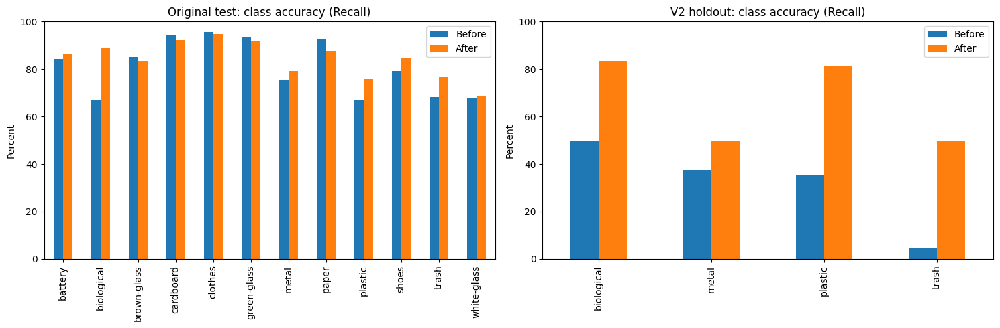

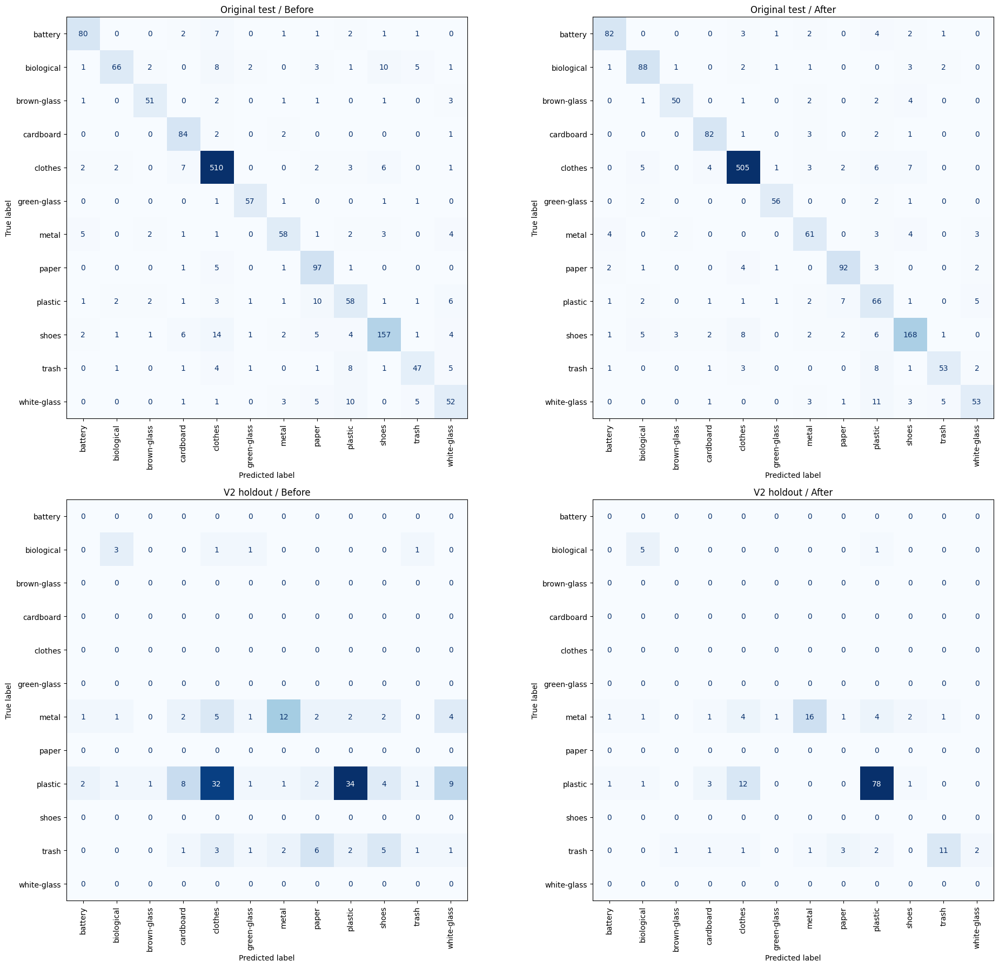

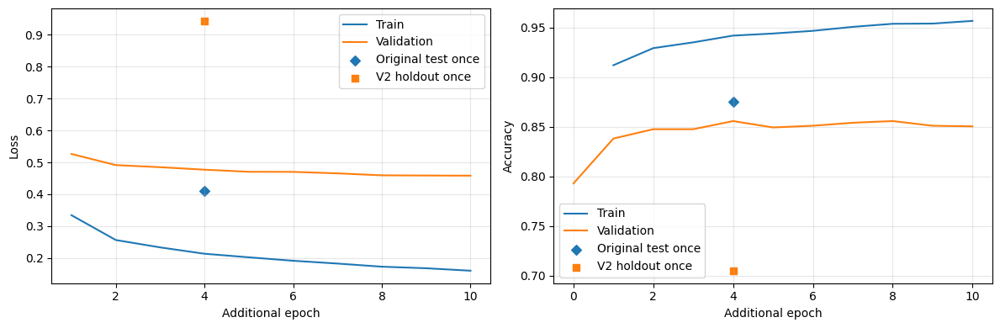

In [12]:
if not RETRAIN_V2:
    # 실제 Colab 로그에 출력된 정밀도의 학습 이력.
    additional_history = pd.DataFrame(
        [(0, None, None, None, 0.793), (1, 0.3342, 0.9119, 0.5262, 0.8381), (2, 0.2564, 0.9291, 0.4914, 0.8475), (3, 0.2333, 0.9349, 0.4848, 0.8475), (4, 0.2134, 0.9417, 0.477, 0.8557), (5, 0.2022, 0.9438, 0.4704, 0.8493), (6, 0.1914, 0.9465, 0.4701, 0.851), (7, 0.1826, 0.9505, 0.4655, 0.854), (8, 0.1728, 0.9536, 0.4593, 0.8557), (9, 0.1679, 0.9538, 0.4587, 0.851), (10, 0.1602, 0.9565, 0.4582, 0.8504)],
        columns=["epoch", "train_loss", "train_acc", "val_loss", "val_acc"]
    )

# 클래스별 정답률 그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, table, title in [
    (axes[0], original_class_comparison, "Original test: class accuracy (Recall)"),
    (axes[1], external_class_comparison, "V2 holdout: class accuracy (Recall)")
]:
    table[["before_accuracy_pct", "after_accuracy_pct"]].plot.bar(ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Percent")
    ax.set_ylim(0, 100)
    ax.legend(["Before", "After"])
plt.tight_layout()
plt.show()

# 기존 시험과 외부 holdout의 혼동행렬: 예측은 여전히 12개 클래스
fig, axes = plt.subplots(2, 2, figsize=(20, 18))
matrices = [
    (before_original[2], before_original[3], "Original test / Before"),
    (after_original[2], after_original[3], "Original test / After"),
    (before_external[2], before_external[3], "V2 holdout / Before"),
    (after_external[2], after_external[3], "V2 holdout / After")
]
for ax, (truths, predictions_list, title) in zip(axes.flat, matrices):
    ConfusionMatrixDisplay.from_predictions(
        truths, predictions_list, labels=list(range(len(classes))),
        display_labels=classes, cmap="Blues", values_format="d",
        xticks_rotation=90, colorbar=False, ax=ax
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

# Epoch 0은 검증만 측정했으므로 train 값은 비워 둠
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "acc"]):
    ax.plot(additional_history["epoch"], additional_history[f"train_{metric}"], label="Train")
    ax.plot(additional_history["epoch"], additional_history[f"val_{metric}"], label="Validation")
    key = "test_loss" if metric == "loss" else "accuracy"
    ax.scatter([selected_additional_epoch], [after_original[0][key]], label="Original test once", marker="D")
    ax.scatter([selected_additional_epoch], [after_external[0][key]], label="V2 holdout once", marker="s")
    ax.set_xlabel("Additional epoch")
    ax.set_ylabel("Loss" if metric == "loss" else "Accuracy")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7 외부 이미지 업로드와 예측

다른 사진을 평가할 때만 실행합니다. Colab에서 이미지 파일을 선택하면 현재 최종 모델의 상위 3개 예측과 점수를 확인할 수 있습니다.

In [ ]:
from io import BytesIO
from PIL import Image, ImageOps, UnidentifiedImageError

# Colab에서는 업로드, VS Code에서는 이미지 경로 입력
try:
    from google.colab import files as colab_files
except ImportError:
    image_path = Path(input("이미지 파일의 전체 경로: ").strip().strip('"'))
    uploaded_images = {image_path.name: image_path.read_bytes()}
else:
    uploaded_images = colab_files.upload()

model.eval()
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

for filename, content in uploaded_images.items():
    try:
        with Image.open(BytesIO(content)) as img:
            # 휴대전화 사진의 회전 정보를 반영하고 RGB로 통일
            image = ImageOps.exif_transpose(img).convert("RGB")
    except (UnidentifiedImageError, OSError):
        print(f"{filename}: 읽을 수 있는 이미지 파일을 선택해 주세요.")
        continue

    # 기존 시험 전처리와 최종 모델을 그대로 사용
    x = test_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu()
    top_probs, top_indices = probabilities.topk(3)

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

    print(f"파일: {filename}")
    for rank, (idx, probability) in enumerate(
        zip(top_indices.tolist(), top_probs.tolist()), start=1
    ):
        print(f"{rank}위: {idx_to_class[idx]} | 예측 확률 {probability:.2%}")